In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("insurance.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


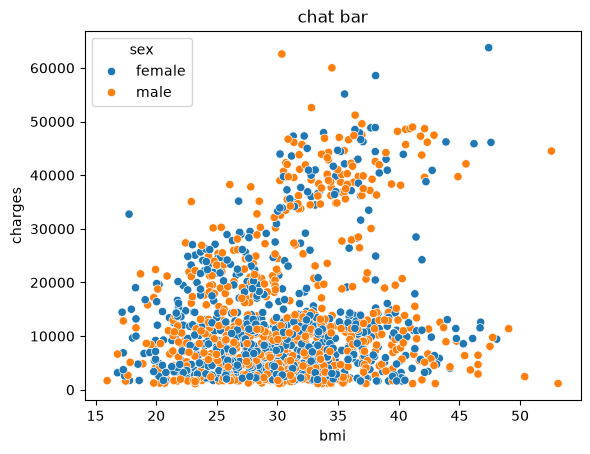

In [3]:

import seaborn as sns
import matplotlib.pyplot as plt

# sns.scatterplot(x=df['bmi'], y=df['charges'], hue= df['smoker'])
# plt.show()

sns.scatterplot(x=df['bmi'], y= df['charges'], hue= df['sex'])
plt.title("chat bar")
plt.show()

In [4]:
# X = df.drop(columns=['charges','region'])
# Y = df['charges']


In [5]:
# X['sex'] = X['sex'].map({'female': 1, 'male':0})
# X['smoker'] = X['smoker'].map({'yes': 1, 'no':0})


In [6]:
# X.head()

In [7]:
# from sklearn.model_selection import train_test_split
# from sklearn.linear_model import LinearRegression


In [8]:
# X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
# X_test.head()

### LinearRegression

In [9]:
# model = LinearRegression()
# model.fit(X_train,Y_train)


In [10]:
# Y_pred = model.predict(X_test)

In [11]:
# Y_pred

In [12]:
df.head()

X = df.drop(columns=['region','charges'])
Y = df['charges']

X['sex'] = X['sex'].map({'female': 1, 'male':0})
X['smoker'] = X['smoker'].map({'yes': 1, 'no':0})


from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
X_test.head()


model = LinearRegression()
model.fit(X_train, Y_train)

pred = model.predict(X_test)
pred






array([ 8554.81711589,  6973.58746745, 36798.60416104,  9417.88282303,
       26871.68031081, 11097.38383938,   145.27608963, 16746.1683771 ,
         747.53414191, 11153.67590722, 28518.15016561,  9292.18345421,
        5460.51975119, 38510.48013003, 40359.30938604, 37223.40538064,
       15316.56711945, 36047.50032223,  9326.29049907, 31400.1559532 ,
        4269.64414373, 10464.66374097,  2719.9260555 ,  6579.53742551,
       11232.00255515, 12472.06793446, 14807.11281089,  6066.19283362,
        9535.69029723,  2377.6983797 ,  9475.05690885, 12963.23366722,
        4706.09057393,  3414.674504  ,  4815.64981654, 12484.17176954,
        2359.13614479,  9161.02061228, 33238.67621442, 32743.41702445,
        4274.58967205,  4229.5442107 , 14435.36485176, 11384.66898976,
        8925.70468583, 12480.09178788,  5154.45787816,  3554.10047649,
       35649.60942684,  9276.25523701, 15971.35991397,  2552.75200479,
       12162.99980138,  1062.65132285, 13551.43771934, 12103.65505529,
      

## Evaluation Metrix
R2 (test data), adjusted R2 (traning data)

In [14]:
from sklearn.metrics import r2_score

r2 = r2_score(Y_test, pred)
r2



0.7811302113434095

In [17]:
n = X_test.shape[0]
p = X_test.shape[1]


ad_r2 = 1-((1-r2)*(n-1)/(n-p-1)
)

ad_r2

0.7769533069797342

### Feature Engineering 

In [18]:
# one hot enconding

In [19]:
X = df.drop(columns=['charges'])
Y= df['charges']

X = pd.get_dummies(X, columns=['region'],drop_first= 'false', dtype= int)

X['sex']=X['sex'].map({'male':0,'female':1})
X['smoker']=X['smoker'].map({'yes':1,'no':0})

In [22]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
X_test.head()


model = LinearRegression()
model.fit(X_train, Y_train)

pred = model.predict(X_test)
r2 = r2_score(Y_test, pred)
r2

0.7835929767120724